# Análisis exploratorio y preparación del dataset de trayectorias académicas

Este notebook realiza la exploración estadística del conjunto de trayectorias académicas generado a partir de registros institucionales. Se analizan las variables disponibles, su distribución y se prepara la matriz de características utilizada posteriormente por los algoritmos de clustering.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

print("Entorno listo")

Entorno listo


In [2]:
ruta_dataset = Path("../data/processed/trayectorias_academicas.csv")

df = pd.read_csv(ruta_dataset)

df.head()

,id_estudiante,periodos_registrados,promedio_global,creditos_totales,cursos_aprobados,cursos_desaprobados,cursos_previo_inicio,promedio_inicial,promedio_final,tendencia,tasa_aprobacion,variabilidad_nota
0,4041859,5,14.545455,117,33,0,0,14.333333,14.428571,0.095238,1.000000,1.002837
1,10610527,5,12.086207,111,48,10,10,14.833333,0.000000,-14.833333,0.827586,5.746958
2,20107537,5,12.228070,111,48,9,9,14.583333,0.000000,-14.583333,0.842105,5.457686
3,20893955,2,5.583333,48,5,7,7,10.166667,1.000000,-9.166667,0.416667,5.759709
4,21063279,8,13.688312,184,76,1,0,12.692308,16.500000,3.807692,0.987013,1.872655


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_estudiante         244 non-null    int64  
 1   periodos_registrados  244 non-null    int64  
 2   promedio_global       244 non-null    float64
 3   creditos_totales      244 non-null    int64  
 4   cursos_aprobados      244 non-null    int64  
 5   cursos_desaprobados   244 non-null    int64  
 6   cursos_previo_inicio  244 non-null    int64  
 7   promedio_inicial      244 non-null    float64
 8   promedio_final        244 non-null    float64
 9   tendencia             244 non-null    float64
 10  tasa_aprobacion       244 non-null    float64
 11  variabilidad_nota     244 non-null    float64
dtypes: float64(6), int64(6)
memory usage: 23.0 KB


In [4]:
df.describe()

,id_estudiante,periodos_registrados,promedio_global,creditos_totales,cursos_aprobados,cursos_desaprobados,cursos_previo_inicio,promedio_inicial,promedio_final,tendencia,tasa_aprobacion,variabilidad_nota
count,2.440000e+02,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000
mean,6.194711e+07,6.573770,13.190643,145.135246,47.118852,4.299180,3.110656,14.022755,11.515165,-2.507590,0.881294,2.964824
std,1.680977e+07,3.236668,2.628901,70.126415,30.453469,6.058412,5.224984,2.116778,6.004777,6.021571,0.176587,2.044468
min,4.041859e+06,2.000000,4.083333,41.000000,4.000000,0.000000,0.000000,0.000000,0.000000,-15.500000,0.241379,0.639940
25%,4.694427e+07,4.000000,11.790552,71.000000,19.750000,0.000000,0.000000,13.666667,9.229167,-3.791667,0.806989,1.461927
50%,7.145250e+07,7.000000,14.078030,151.000000,44.500000,1.000000,0.000000,14.333333,14.309524,-0.258333,0.983609,1.722448
75%,7.486244e+07,10.000000,15.051890,219.250000,76.500000,7.000000,6.000000,15.020833,15.666667,1.000000,1.000000,4.661736
max,7.854754e+07,12.000000,16.612245,270.000000,110.000000,26.000000,25.000000,17.000000,18.500000,13.000000,1.000000,8.147783


In [5]:
df["periodos_registrados"].value_counts().sort_index()

periodos_registrados
2     41
3     19
4     21
5     26
6     12
7     22
8      5
9     13
10    71
11    10
12     4
Name: count, dtype: int64

In [6]:
variables = [
    "periodos_registrados",
    "promedio_global",
    "creditos_totales",
    "cursos_aprobados",
    "cursos_desaprobados",
    "cursos_previo_inicio",
    "promedio_inicial",
    "promedio_final",
    "tendencia",
    "tasa_aprobacion",
    "variabilidad_nota"
]

matriz_corr = df[variables].corr()

matriz_corr

,periodos_registrados,promedio_global,creditos_totales,cursos_aprobados,cursos_desaprobados,cursos_previo_inicio,promedio_inicial,promedio_final,tendencia,tasa_aprobacion,variabilidad_nota
periodos_registrados,1.000000,0.456737,0.991387,0.908375,-0.193680,-0.215474,0.116963,0.466565,0.424147,0.496526,-0.377533
promedio_global,0.456737,1.000000,0.438995,0.438549,-0.785867,-0.768460,0.437518,0.836065,0.679931,0.944518,-0.857068
creditos_totales,0.991387,0.438995,1.000000,0.913706,-0.178942,-0.201956,0.103698,0.459879,0.422143,0.487689,-0.362799
cursos_aprobados,0.908375,0.438549,0.913706,1.000000,-0.180215,-0.212492,0.108662,0.419876,0.380506,0.490774,-0.381058
cursos_desaprobados,-0.193680,-0.785867,-0.178942,-0.180215,1.000000,0.943934,-0.316168,-0.708753,-0.595633,-0.773365,0.800966
cursos_previo_inicio,-0.215474,-0.768460,-0.201956,-0.212492,0.943934,1.000000,-0.285930,-0.722102,-0.619574,-0.740431,0.828208
promedio_inicial,0.116963,0.437518,0.103698,0.108662,-0.316168,-0.285930,1.000000,0.168313,-0.183689,0.370290,-0.290139
promedio_final,0.466565,0.836065,0.459879,0.419876,-0.708753,-0.722102,0.168313,1.000000,0.938044,0.805419,-0.851610
tendencia,0.424147,0.679931,0.422143,0.380506,-0.595633,-0.619574,-0.183689,0.938044,1.000000,0.673004,-0.747242
tasa_aprobacion,0.496526,0.944518,0.487689,0.490774,-0.773365,-0.740431,0.370290,0.805419,0.673004,1.000000,-0.866756


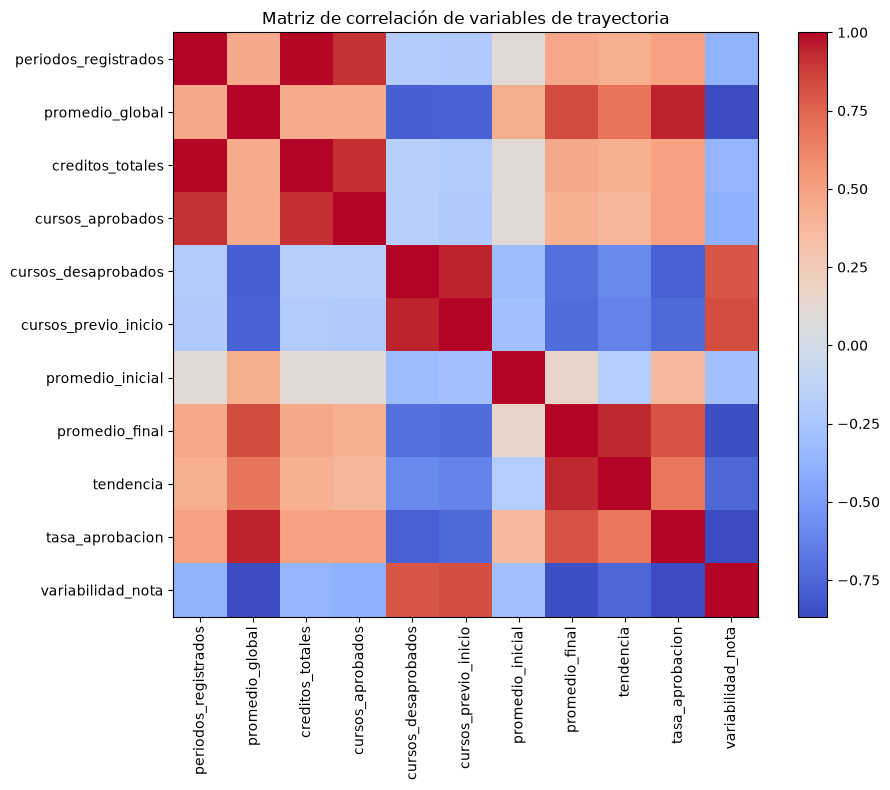

In [7]:
plt.figure(figsize=(10,8))

plt.imshow(
    matriz_corr,
    cmap="coolwarm"
)

plt.colorbar()

plt.xticks(
    range(len(variables)),
    variables,
    rotation=90
)

plt.yticks(
    range(len(variables)),
    variables
)

plt.title("Matriz de correlación de variables de trayectoria")

plt.tight_layout()

plt.show()

In [8]:
variables_clustering = [
    "periodos_registrados",
    "promedio_global",
    "creditos_totales",
    "cursos_aprobados",
    "cursos_desaprobados",
    "cursos_previo_inicio",
    "promedio_inicial",
    "promedio_final",
    "tendencia",
    "tasa_aprobacion",
    "variabilidad_nota"
]


X = df[variables_clustering]

X.head()

,periodos_registrados,promedio_global,creditos_totales,cursos_aprobados,cursos_desaprobados,cursos_previo_inicio,promedio_inicial,promedio_final,tendencia,tasa_aprobacion,variabilidad_nota
0,5,14.545455,117,33,0,0,14.333333,14.428571,0.095238,1.000000,1.002837
1,5,12.086207,111,48,10,10,14.833333,0.000000,-14.833333,0.827586,5.746958
2,5,12.228070,111,48,9,9,14.583333,0.000000,-14.583333,0.842105,5.457686
3,2,5.583333,48,5,7,7,10.166667,1.000000,-9.166667,0.416667,5.759709
4,8,13.688312,184,76,1,0,12.692308,16.500000,3.807692,0.987013,1.872655


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[-0.48723118,  0.51641225, -0.40203221, -0.46457346, -0.71108023,
        -0.59656631,  0.14702383,  0.48617867,  0.43313908,  0.67360301,
        -0.96162883],
       [-0.48723118, -0.42097665, -0.48776785,  0.0289937 ,  0.94291   ,
         1.32124898,  0.38371746, -1.92160918, -2.05113896, -0.30477079,
         1.36360803],
       [-0.48723118, -0.36690277, -0.48776785,  0.0289937 ,  0.77751098,
         1.12946745,  0.26537064, -1.92160918, -2.00953622, -0.22238142,
         1.22182732],
       [-1.41601563, -2.89967031, -1.38799205, -1.38589884,  0.44671293,
         0.74590439, -1.82542303, -1.7547328 , -1.10814347, -2.63656168,
         1.36985748],
       [ 0.44155326,  0.18969599,  0.55534908,  0.95031907, -0.5456812 ,
        -0.59656631, -0.62981678,  0.83185118,  1.05093218,  0.59990732,
        -0.53530493]])

In [10]:
X_clustering = pd.DataFrame(
    X_scaled,
    columns=variables_clustering
)

X_clustering.to_csv(
    "../data/processed/X_clustering.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Matriz de clustering guardada")

Matriz de clustering guardada


In [11]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
periodos_registrados,244.0,6.573770,3.236668,2.000000,4.000000,7.000000,10.000000,12.000000
promedio_global,244.0,13.190643,2.628901,4.083333,11.790552,14.078030,15.051890,16.612245
creditos_totales,244.0,145.135246,70.126415,41.000000,71.000000,151.000000,219.250000,270.000000
cursos_aprobados,244.0,47.118852,30.453469,4.000000,19.750000,44.500000,76.500000,110.000000
cursos_desaprobados,244.0,4.299180,6.058412,0.000000,0.000000,1.000000,7.000000,26.000000
cursos_previo_inicio,244.0,3.110656,5.224984,0.000000,0.000000,0.000000,6.000000,25.000000
promedio_inicial,244.0,14.022755,2.116778,0.000000,13.666667,14.333333,15.020833,17.000000
promedio_final,244.0,11.515165,6.004777,0.000000,9.229167,14.309524,15.666667,18.500000
tendencia,244.0,-2.507590,6.021571,-15.500000,-3.791667,-0.258333,1.000000,13.000000
tasa_aprobacion,244.0,0.881294,0.176587,0.241379,0.806989,0.983609,1.000000,1.000000


In [12]:

print("Dimensiones:", X_clustering.shape)
print("Valores faltantes:", X_clustering.isnull().sum().sum())

Dimensiones: (244, 11)
Valores faltantes: 0
